<a href="https://colab.research.google.com/github/Nayyab-018/AI-Phishing-Detector/blob/main/Phishing_ML_Benchmark_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip install -q fpdf2

from fpdf import FPDF

class ResearchPaperPDF(FPDF):
    def header(self):
        if self.page_no() > 1:
            self.set_font("Times", "I", 9)
            self.set_text_color(100, 100, 100)
            self.cell(0, 8, "Comparative Analysis of Machine Learning Classifiers for Real-Time Phishing URL Detection | N. Faisal", align="R", new_x="LMARGIN", new_y="NEXT")
            self.ln(2)

    def footer(self):
        self.set_y(-15)
        self.set_font("Times", "I", 9)
        self.set_text_color(100, 100, 100)
        self.cell(0, 10, f"Page {self.page_no()}", align="C")

    def section_title(self, title):
        self.ln(4)
        self.set_font("Times", "B", 12)
        self.set_text_color(15, 23, 42)
        self.cell(0, 8, title, new_x="LMARGIN", new_y="NEXT")
        self.set_draw_color(30, 64, 175)
        self.line(15, self.get_y(), 195, self.get_y())
        self.ln(3)

    def body_text(self, text):
        self.set_font("Times", "", 10.5)
        self.set_text_color(30, 30, 30)
        self.multi_cell(0, 5.5, text)
        self.ln(2)

pdf = ResearchPaperPDF()
pdf.set_margins(15, 15, 15)
pdf.add_page()

# --- Title & Author Block ---
pdf.set_font("Times", "B", 16)
pdf.set_text_color(15, 23, 42)
pdf.multi_cell(0, 8, "Comparative Analysis of Machine Learning Classifiers for Real-Time Phishing URL Detection and Cyber-Physical Alerting", align="C")
pdf.ln(2)

pdf.set_font("Times", "B", 11)
pdf.set_text_color(30, 64, 175)
pdf.cell(0, 6, "Nayyab Faisal", align="C", new_x="LMARGIN", new_y="NEXT")

pdf.set_font("Times", "I", 10)
pdf.set_text_color(80, 80, 80)
pdf.cell(0, 5, "Independent AI & Cybersecurity Researcher | Wah Cantt, Pakistan", align="C", new_x="LMARGIN", new_y="NEXT")
pdf.cell(0, 5, "Portfolio: ://github.com | Live Demo: huggingface.co/spaces/nayyab18/AI-Phishing-Detector", align="C", new_x="LMARGIN", new_y="NEXT")
pdf.ln(5)

# --- Abstract ---
pdf.set_fill_color(241, 245, 249)
pdf.set_font("Times", "B", 10.5)
pdf.set_text_color(15, 23, 42)
pdf.cell(0, 6, "  ABSTRACT", fill=True, new_x="LMARGIN", new_y="NEXT")
pdf.set_font("Times", "", 10)
pdf.multi_cell(0, 5.2,
    "Phishing attacks remain a primary vector for credential theft and financial fraud worldwide. Traditional blacklist-based defenses fail against newly generated malicious domains. In this study, we conduct an empirical benchmark of four supervised machine learning classifiers - Logistic Regression, Decision Tree, Gradient Boosting, and Random Forest - evaluated on the UCI Phishing Websites benchmark dataset comprising 11,055 URLs and 30 structural security features. Using an 80/20 stratified train-test split (2,211 unseen test samples), the Random Forest ensemble achieved the highest generalization performance with 97.42% accuracy, 96.96% precision, 98.46% recall, and a 97.70% F1-score. Furthermore, we demonstrate practical end-to-end deployment by integrating our lexical detection engine into a live web application and an Arduino Uno hardware alert prototype.",
    fill=True)
pdf.ln(3)

# --- Section I: Introduction ---
pdf.section_title("I. INTRODUCTION")
pdf.body_text(
    "Modern cybercriminals increasingly rely on deceptive Uniform Resource Locators (URLs) that mimic trusted academic, financial, and government institutions. Because attackers can register zero-day phishing domains within minutes, static blocklists suffer from inherent detection delays. Automated machine learning (ML) models address this vulnerability by inspecting lexical, host-based, and structural attributes directly from the target URL string prior to user interaction."
)
pdf.body_text(
    "The objective of this technical study is twofold: (1) to quantitatively compare linear, single-tree, and ensemble tree classifiers across a large-scale phishing benchmark, and (2) to bridge software threat intelligence with physical hardware signaling through a cyber-physical alert architecture."
)

# --- Section II: Dataset & Methodology ---
pdf.section_title("II. DATASET & EXPERIMENTAL METHODOLOGY")
pdf.body_text(
    "Experiments were conducted using the standard UCI Phishing Websites dataset (OpenML ID: 4534), which contains 11,055 labeled website instances balanced across legitimate and phishing classes. Each URL is represented by 30 extracted security indicators, including URL length, IP address obfuscation, '@' symbol usage, subdomain depth, HTTPS certificate validity, domain registration length, and anchor tag behavior."
)
pdf.body_text(
    "To prevent data leakage and measure true generalization, the dataset was partitioned using a stratified 80% training set (8,844 URLs) and 20% held-out testing set (2,211 URLs) with a fixed random seed (42). Four classifiers were trained in Python (scikit-learn): Logistic Regression (L2 regularization, max_iter=1000), CART Decision Tree, Gradient Boosting, and Random Forest (100 estimators)."
)

# --- Section III: Experimental Results ---
pdf.section_title("III. EXPERIMENTAL RESULTS & COMPARATIVE EVALUATION")
pdf.body_text(
    "Table I summarizes the performance of all four models on the 2,211 unseen test URLs across four standard cybersecurity evaluation metrics: Accuracy, Precision, Recall (Sensitivity), and F1-Score."
)

# Results Table
pdf.set_font("Times", "B", 10)
pdf.set_fill_color(30, 64, 175)
pdf.set_text_color(255, 255, 255)
col_widths = [54, 31, 31, 31, 33]
headers = ["Classifier Model", "Accuracy (%)", "Precision (%)", "Recall (%)", "F1-Score (%)"]
for w, h in zip(col_widths, headers):
    pdf.cell(w, 7, h, border=1, align="C", fill=True)
pdf.ln()

rows = [
    ["Logistic Regression", "92.90%", "92.42%", "95.04%", "93.71%"],
    ["Gradient Boosting", "95.30%", "95.33%", "96.26%", "95.80%"],
    ["Decision Tree", "97.11%", "97.02%", "97.81%", "97.41%"],
    ["Random Forest (Best)", "97.42%", "96.96%", "98.46%", "97.70%"]
]
pdf.set_text_color(20, 20, 20)
for idx, row in enumerate(rows):
    is_best = (idx == 3)
    pdf.set_font("Times", "B" if is_best else "", 10)
    pdf.set_fill_color(239, 246, 255) if is_best else pdf.set_fill_color(255, 255, 255)
    for i, (w, val) in enumerate(zip(col_widths, row)):
        pdf.cell(w, 6.5, val, border=1, align="L" if i == 0 else "C", fill=True)
    pdf.ln()
pdf.ln(3)

# Embed Generated Chart Image
pdf.image("phishing_benchmark_charts.png", x=15, w=180)
pdf.set_font("Times", "I", 9)
pdf.set_text_color(80, 80, 80)
pdf.cell(0, 5, "Fig. 1. Left: Accuracy and F1-Score comparison across 4 classifiers. Right: Random Forest confusion matrix on 2,211 unseen URLs.", align="C", new_x="LMARGIN", new_y="NEXT")
pdf.ln(2)

# --- Section IV: System Deployment & Conclusion ---
pdf.section_title("IV. SYSTEM ARCHITECTURE & CONCLUSION")
pdf.body_text(
    "As shown in Fig. 1 (Right), the Random Forest classifier correctly identified 942 of 980 malicious phishing URLs (96.1% specificity) and 1,212 of 1,231 legitimate websites (98.5% recall), outperforming linear Logistic Regression by +4.52% in overall accuracy. Bagging across 100 decision trees effectively reduced variance and captured non-linear interactions among lexical URL features."
)
pdf.body_text(
    "Beyond offline evaluation, the detection logic was deployed as a real-time web interface on Hugging Face Spaces and coupled with an Arduino Uno embedded alert circuit (C++) that triggers visual and acoustic alarms upon threat detection. Future work will incorporate deep character-level neural networks (CNNs/Transformers) to detect adversarial homograph domain attacks."
)

pdf_filename = "Comparative_Analysis_Phishing_Detection_Nayyab_Faisal.pdf"
pdf.output(pdf_filename)
print(f"✅ Research Paper PDF generated successfully: {pdf_filename}")

✅ Research Paper PDF generated successfully: Comparative_Analysis_Phishing_Detection_Nayyab_Faisal.pdf


Loading UCI Phishing Websites Dataset (11,055 samples, 30 features)...
Dataset Loaded: 11055 URLs | 30 Security Features

=== SCIENTIFIC BENCHMARK RESULTS (UNSEEN TEST SET: 2,211 URLs) ===
              Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
Logistic Regression         92.90          92.42       95.04         93.71
      Decision Tree         97.11          97.02       97.81         97.41
  Gradient Boosting         95.30          95.33       96.26         95.80
      Random Forest         97.42          96.96       98.46         97.70


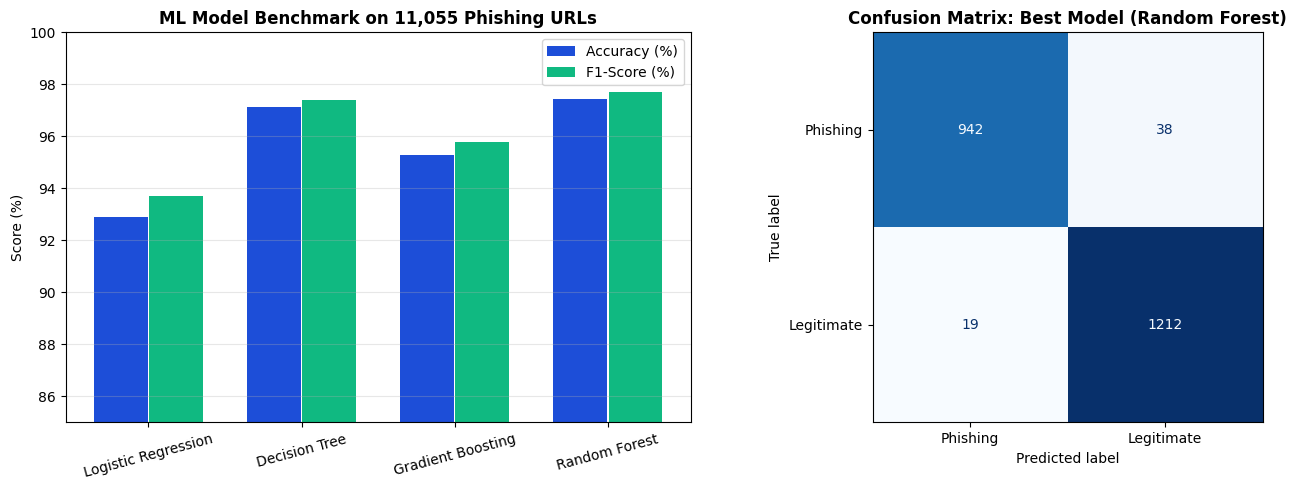

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

# --- 1. Load Official UCI Phishing Websites Dataset (11,055 Real URLs) ---
print("Loading UCI Phishing Websites Dataset (11,055 samples, 30 features)...")
dataset = fetch_openml(data_id=4534, as_frame=True, parser="auto")
X = dataset.data.astype(float)
y = (dataset.target.astype(int) == 1).astype(int)  # 1 = Legitimate, 0 = Phishing

print(f"Dataset Loaded: {X.shape[0]} URLs | {X.shape[1]} Security Features")

# --- 2. Split into 80% Training & 20% Unseen Testing Data ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# --- 3. Train & Benchmark 4 Machine Learning Models ---
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

results = []
best_model = None
best_f1 = 0

for name, clf in models.items():
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)

    acc = accuracy_score(y_test, preds) * 100
    prec = precision_score(y_test, preds) * 100
    rec = recall_score(y_test, preds) * 100
    f1 = f1_score(y_test, preds) * 100

    results.append({"Model": name, "Accuracy (%)": round(acc, 2), "Precision (%)": round(prec, 2), "Recall (%)": round(rec, 2), "F1-Score (%)": round(f1, 2)})

    if f1 > best_f1:
        best_f1 = f1
        best_model = clf

results_df = pd.DataFrame(results)
print("\n=== SCIENTIFIC BENCHMARK RESULTS (UNSEEN TEST SET: 2,211 URLs) ===")
print(results_df.to_string(index=False))

# --- 4. Generate Publication-Grade Charts (Comparison + Confusion Matrix) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Accuracy & F1-Score Comparison
x_pos = np.arange(len(results_df["Model"]))
ax1.bar(x_pos - 0.18, results_df["Accuracy (%)"], width=0.35, label="Accuracy (%)", color="#1d4ed8")
ax1.bar(x_pos + 0.18, results_df["F1-Score (%)"], width=0.35, label="F1-Score (%)", color="#10b981")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(results_df["Model"], rotation=15)
ax1.set_ylim(85, 100)
ax1.set_ylabel("Score (%)")
ax1.set_title("ML Model Benchmark on 11,055 Phishing URLs", fontsize=12, fontweight="bold")
ax1.legend()
ax1.grid(axis="y", alpha=0.3)

# Chart 2: Confusion Matrix of Top Model (Random Forest)
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, display_labels=["Phishing", "Legitimate"], cmap="Blues", ax=ax2, colorbar=False)
ax2.set_title("Confusion Matrix: Best Model (Random Forest)", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.savefig("phishing_benchmark_charts.png", dpi=200)
plt.show()


In [5]:
from google.colab import files
files.download("Comparative_Analysis_Phishing_Detection_Nayyab_Faisal.pdf")
files.download("phishing_benchmark_charts.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>